# Notebook de documentacion del datasey y tratamiento datos.

## Equipo
- Alumno 1 : Lucas Diaz Celauro
- Alumno 2 : Amanda Tardugno

## Configuración

`MODO_PRUEBA = True` corre todo de punta a punta con un entrenamiento mínimo (una época de pocos lotes), para verificar que la notebook no tiene errores en cualquier máquina. La corrida que se entrega tiene `MODO_PRUEBA = False` y se hizo en GPU.

In [1]:
# Bibliotecas, semilla, dispositivo y parámetros que se usan en toda la notebook
import sys
import copy
import json
import time
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="`estimate` is deprecated")
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import onnxruntime as ort
from dotenv import dotenv_values
from sklearn.metrics import roc_curve, auc

sys.path.insert(0, "src")
from lib.models.custom_cnn import CustomFaceCNN, SoftmaxHead, ArcFaceHead, export_onnx
from lib.models.augmentation import build_train_augmentation, augment_face
from lib.services.face_service import FaceService
from lib.schemas import AlignedFace

MODO_PRUEBA = True

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

RUTA_INTERMEDIOS = Path("data") / "intermedios"
CONFIG_APP = dotenv_values(".env.local.example")
RUTA_MODELOS = Path(CONFIG_APP["MODEL_PATH"])
EMBEDDING_DIM = int(CONFIG_APP["EMBEDDING_DIM"])
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROVEEDORES = ["CUDAExecutionProvider", "CPUExecutionProvider"] if DISPOSITIVO.type == "cuda" else ["CPUExecutionProvider"]
ort.set_default_logger_severity(3)
print(f"MODO_PRUEBA = {MODO_PRUEBA}  |  dispositivo: {DISPOSITIVO}" + (f" ({torch.cuda.get_device_name(0)})" if DISPOSITIVO.type == "cuda" else "") + f"  |  torch {torch.__version__}  |  onnxruntime {ort.__version__}")

MODO_PRUEBA = True  |  dispositivo: cpu  |  torch 2.11.0+cpu  |  onnxruntime 1.24.4


## Datos

In [2]:
# Particiones de la notebook 1: la columna indice es la fila de embeddings_arcface.npy, que tiene los embeddings del Modelo B
splits = pd.read_csv(RUTA_INTERMEDIOS / "splits.csv")
emb_arcface_todos = np.load(RUTA_INTERMEDIOS / "embeddings_arcface.npy")
pares_oficiales = pd.read_csv(RUTA_INTERMEDIOS / "pares_oficiales.csv")
splits.groupby("split", sort=False).agg(personas=("persona", "nunique"), caras=("ruta", "size"))

,personas,caras
split,,
pins_train,90,12428
pins_val,90,2188
pins_test,15,2235
lfw_val,2835,6975
lfw_test,2834,6040


In [3]:
def cargar_caras(filas):
    """Caras alineadas (BGR uint8, 112×112) de las filas, en el mismo orden."""
    return np.stack([cv2.imread(r) for r in filas["ruta_alineada"]])

In [4]:
# Caras de entrenamiento y validación de Pins en memoria, con la identidad como número de clase
entrenamiento = splits[splits["split"] == "pins_train"].reset_index(drop=True)
validacion = splits[splits["split"] == "pins_val"].reset_index(drop=True)
clases = sorted(entrenamiento["persona"].unique())
clase_de = {p: i for i, p in enumerate(clases)}
x_train, y_train = cargar_caras(entrenamiento), entrenamiento["persona"].map(clase_de).to_numpy()
x_val, y_val = cargar_caras(validacion), validacion["persona"].map(clase_de).to_numpy()
assert set(validacion["persona"]) == set(clases)
print(f"train: {x_train.shape}  |  validación: {x_val.shape}  |  clases: {len(clases)}")

train: (12428, 112, 112, 3)  |  validación: (2188, 112, 112, 3)  |  clases: 90


## Modelo A: CNN custom

La CNN está en `src/lib/models/custom_cnn.py`, para que el backend pueda cargarla (sección 3.5 del enunciado). Es un backbone de cuatro bloques convolucionales (dos convoluciones 3×3 con BatchNorm y ReLU, y un max pooling que reduce la resolución a la mitad), con 32, 64, 128 y 256 canales: de 112×112 se llega a 7×7. Después vienen un global average pooling, Dropout de 0,2, una capa lineal a 512 dimensiones y BatchNorm. El enunciado sugiere de 4 a 6 bloques; con unas 12.000 caras de 90 personas se usa el mínimo, para limitar el sobreajuste. BatchNorm estabiliza el entrenamiento desde cero y permite una tasa de aprendizaje alta. El global average pooling reduce los 7×7×256 valores a 256: aplanarlos y pasarlos a 512 sumaría unos 6,4 millones de parámetros, cinco veces la red entera. El embedding tiene 512 dimensiones, igual que ArcFace, para que cambiar de modelo en la app sea solo cambiar `MODEL_NAME` en el `.env`.

La entrada es la del pipeline de la app (`FaceService.preprocess_face`: RGB, `(x − 127,5) / 127,5`, CHW), así que el entrenamiento y la inferencia normalizan igual por construcción.

Se comparan dos formas de entrenar el embedding, con la misma red:

- **Softmax:** una capa lineal clasifica a las 90 personas con entropía cruzada, y el embedding es la capa previa al clasificador. Es el enfoque más simple.
- **ArcFace:** los pesos de la última capa son centros de clase sobre la hiperesfera, y se suma un margen angular m = 0,5 al ángulo de la clase correcta, con escala s = 64. Obliga a que las caras de una persona queden más juntas y las de personas distintas más separadas en ángulo, que es lo que mide el coseno de la app.

Las dos cabezas solo se usan para entrenar: lo que se exporta es la red hasta el embedding.

In [5]:
# Arquitectura, cantidad de parámetros y forma de la salida
red = CustomFaceCNN()
parametros = sum(p.numel() for p in red.parameters())
print(red)
print(f"Parámetros: {parametros:,}".replace(",", ".") + f" ({parametros * 4 / 1e6:.1f} MB en float32)  |  salida: {tuple(red.eval()(torch.zeros(2, 3, 112, 112)).shape)}")

CustomFaceCNN(
  (backbone): Sequential(
    (0): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (layers): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2

### Entrenamiento

Se usa SGD con momentum 0,9, una tasa inicial de 0,1, weight decay de 5e-4 y una tasa que baja con coseno hasta el final, la receta habitual para ArcFace. Los parámetros de la cabeza entran al optimizador junto con los de la red: en ArcFace, los centros de clase son parámetros de la cabeza, y si no se incluyen quedan fijos en su valor inicial. Lotes de 128 caras, con la augmentation de la notebook 1 solo sobre train. Cada época se mide la pérdida y el acierto en train y en validación (en modo `eval`, como corre la app). Se guarda el mejor estado según el acierto en validación, y el entrenamiento se corta si no mejora en 5 épocas seguidas. El acierto de ArcFace se mide sin margen, porque el margen solo existe al entrenar.

In [6]:
# Hiperparámetros (en modo prueba: una época de pocos lotes)
EPOCAS = 1 if MODO_PRUEBA else 40
PACIENCIA = 5
TAM_LOTE = 128
LR = 0.1
LOTES_MAXIMOS = 5 if MODO_PRUEBA else None
aumento = build_train_augmentation()
aumento.set_random_seed(SEMILLA)
RUTA_CHECKPOINTS = RUTA_INTERMEDIOS / "checkpoints"  # en data/, que git ignora: los pesos no se suben al repo
RUTA_CHECKPOINTS.mkdir(parents=True, exist_ok=True)

In [7]:
def lotes(caras, etiquetas, aumentar, rng):
    """Lotes de tensores listos para la red (con augmentation solo si se pide), en orden aleatorio si aumentar es True."""
    orden = rng.permutation(len(caras)) if aumentar else np.arange(len(caras))
    for k, inicio in enumerate(range(0, len(orden), TAM_LOTE)):
        if LOTES_MAXIMOS is not None and k >= LOTES_MAXIMOS:
            break
        idx = orden[inicio:inicio + TAM_LOTE]
        lote = [augment_face(caras[i], aumento) if aumentar else caras[i] for i in idx]
        x = torch.from_numpy(np.concatenate([FaceService.preprocess_face(c) for c in lote])).to(DISPOSITIVO)
        yield x, torch.from_numpy(etiquetas[idx]).to(DISPOSITIVO)

In [8]:
def entrenar(nombre, cabeza):
    """Entrena la CNN con la cabeza dada, guarda el mejor estado según el acierto en validación y devuelve la red y la historia."""
    torch.manual_seed(SEMILLA)
    rng = np.random.default_rng(SEMILLA)
    red, cabeza = CustomFaceCNN().to(DISPOSITIVO), cabeza.to(DISPOSITIVO)
    optimizador = torch.optim.SGD(list(red.parameters()) + list(cabeza.parameters()), lr=LR, momentum=0.9, weight_decay=5e-4)
    planificador = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=EPOCAS)
    historia, mejor, sin_mejora = [], -1.0, 0
    for epoca in range(1, EPOCAS + 1):
        inicio = time.time()
        medidas = {}
        for fase, caras, etiquetas in [("train", x_train, y_train), ("validación", x_val, y_val)]:
            entrenando = fase == "train"
            red.train(entrenando); cabeza.train(entrenando)
            perdida_total, aciertos, n = 0.0, 0, 0
            with torch.set_grad_enabled(entrenando):
                for x, y in lotes(caras, etiquetas, aumentar=entrenando, rng=rng):
                    embedding = red(x)
                    perdida = F.cross_entropy(cabeza(embedding, y), y)
                    if entrenando:
                        optimizador.zero_grad()
                        perdida.backward()
                        optimizador.step()
                    with torch.no_grad():
                        aciertos += (cabeza(embedding, None).argmax(dim=1) == y).sum().item()
                    perdida_total += perdida.item() * len(y)
                    n += len(y)
            medidas[f"pérdida {fase}"] = perdida_total / n
            medidas[f"acierto {fase}"] = aciertos / n
        planificador.step()
        historia.append({"época": epoca, **medidas, "segundos": time.time() - inicio})
        print(f"{nombre} | época {epoca:2d} | " + " | ".join(f"{k} {v:.3f}" for k, v in medidas.items()) + f" | {time.time() - inicio:.0f} s")
        if medidas["acierto validación"] > mejor:
            mejor, sin_mejora = medidas["acierto validación"], 0
            torch.save(red.state_dict(), RUTA_CHECKPOINTS / f"{nombre}.pt")
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                print(f"Early stopping: {PACIENCIA} épocas sin mejorar en validación")
                break
    red.load_state_dict(torch.load(RUTA_CHECKPOINTS / f"{nombre}.pt", map_location=DISPOSITIVO))
    return red.eval(), pd.DataFrame(historia)

In [9]:
# Experimento 1: cabeza softmax
red_softmax, historia_softmax = entrenar("softmax", SoftmaxHead(EMBEDDING_DIM, len(clases)))

softmax | época  1 | pérdida train 4.695 | acierto train 0.044 | pérdida validación 4.484 | acierto validación 0.000 | 19 s


In [10]:
# Experimento 2: cabeza ArcFace (s = 64, m = 0,5)
red_arcface, historia_arcface = entrenar("arcface", ArcFaceHead(EMBEDDING_DIM, len(clases)))

arcface | época  1 | pérdida train 40.970 | acierto train 0.042 | pérdida validación 58.323 | acierto validación 0.000 | 22 s


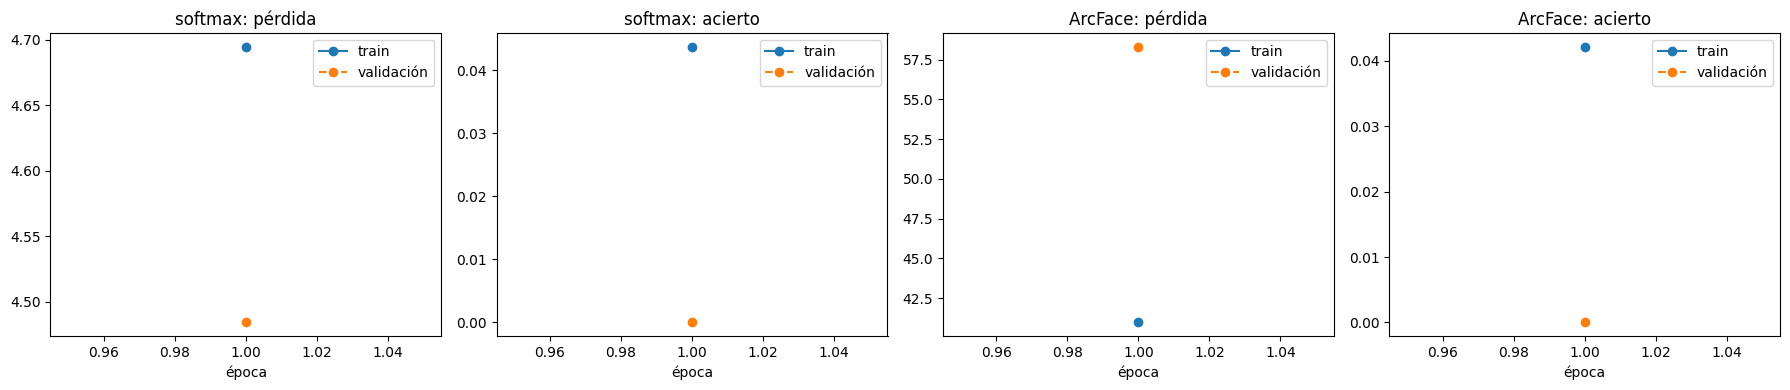

In [11]:
# Curvas de pérdida y acierto en train y validación de los dos experimentos
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for fila, (nombre, historia) in enumerate([("softmax", historia_softmax), ("ArcFace", historia_arcface)]):
    for col, medida in enumerate(["pérdida", "acierto"]):
        eje = ejes[2 * fila + col]
        for fase, estilo in [("train", "-"), ("validación", "--")]:
            eje.plot(historia["época"], historia[f"{medida} {fase}"], estilo, marker="o", label=fase)
        eje.set(title=f"{nombre}: {medida}", xlabel="época"); eje.legend()
plt.tight_layout()
plt.show()

*Figura 1. Pérdida y acierto en train y en validación por época, para la CNN entrenada con cabeza softmax (izquierda) y con cabeza ArcFace (derecha).*

*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

### Embeddings de la CNN

In [12]:
def embeddings_de(red, filas):
    """Embeddings L2-normalizados de la red para las caras alineadas de las filas, con el preprocesamiento de la app."""
    salida = []
    with torch.no_grad():
        for inicio in range(0, len(filas), 256):
            lote = cargar_caras(filas.iloc[inicio:inicio + 256])
            x = torch.from_numpy(np.concatenate([FaceService.preprocess_face(c) for c in lote])).to(DISPOSITIVO)
            salida.append(F.normalize(red(x), dim=1).cpu().numpy())
    return np.concatenate(salida)

In [13]:
# Embeddings de los dos experimentos y de ArcFace para los conjuntos de evaluación, en el mismo orden que splits
evaluacion = splits[splits["split"].isin(["pins_test", "lfw_val", "lfw_test"])].reset_index(drop=True)
emb = {
    "ArcFace (preentrenado)": emb_arcface_todos[evaluacion["indice"]],
    "CNN softmax": embeddings_de(red_softmax, evaluacion),
    "CNN ArcFace": embeddings_de(red_arcface, evaluacion),
}
print({k: v.shape for k, v in emb.items()})

{'ArcFace (preentrenado)': (15250, 512), 'CNN softmax': (15250, 512), 'CNN ArcFace': (15250, 512)}


## Modelo B: ArcFace preentrenado

El Modelo B es el paquete `buffalo_l` de InsightFace, el mismo que usa la app: el detector SCRFD (`det_10g.onnx`, la elección de la notebook 1) y el reconocedor `w600k_r50.onnx`, una ResNet-50 entrenada con la pérdida ArcFace sobre WebFace600K (unas 600.000 personas de fotos de internet). Devuelve un embedding de 512 dimensiones. Se usa sin reentrenar: los embeddings son los que se calcularon en la notebook 1 con el `FaceService` de la app, sobre las mismas caras alineadas que ve la CNN. Los modelos de InsightFace son de uso **no comercial y de investigación**. Como se entrenó con fotos de famosos, puede haber visto a algunas personas de los conjuntos de test, lo que le daría una ventaja que la CNN no tiene.

## Protocolo de evaluación

Los dos modelos se evalúan sobre los mismos pares y las mismas galerías, en tres conjuntos de personas que la CNN nunca vio: `pins_test` (15 personas del mismo dominio que el entrenamiento), `lfw_val` (para calibrar el umbral) y `lfw_test` (otro dominio). Los pares positivos son todos los de cada persona, con un máximo de 50 por persona para que alguien con cientos de fotos no domine. Los negativos son 20.000 pares de dos personas distintas, elegidas al azar entre personas (no entre fotos), por el mismo motivo. Que haya más negativos que positivos no cambia la ROC, que usa tasas, y permite medir el acierto con falsos positivos de hasta 1 en 1.000 con una muestra razonable.

In [14]:
# Pares positivos (con tope por persona) y negativos (personas distintas sorteadas por persona), iguales para todos los modelos
MAX_POSITIVOS_POR_PERSONA = 50
NEGATIVOS = 20000

def armar_pares(conjunto, rng):
    """Índices (filas de evaluacion) de pares positivos y negativos de un conjunto, y su etiqueta (1 = misma persona)."""
    filas = evaluacion[evaluacion["split"] == conjunto]
    grupos = {p: g.index.to_numpy() for p, g in filas.groupby("persona")}
    pos = []
    for indices in grupos.values():
        if len(indices) < 2:
            continue
        i, j = np.triu_indices(len(indices), k=1)
        elegidos = rng.choice(len(i), min(len(i), MAX_POSITIVOS_POR_PERSONA), replace=False)
        pos += list(zip(indices[i[elegidos]], indices[j[elegidos]]))
    personas = np.array(list(grupos))
    neg = []
    while len(neg) < NEGATIVOS:
        a, b = rng.choice(personas, 2, replace=False)
        neg.append((rng.choice(grupos[a]), rng.choice(grupos[b])))
    pares = np.array(pos + neg)
    return pares[:, 0], pares[:, 1], np.r_[np.ones(len(pos)), np.zeros(len(neg))]

rng_pares = np.random.default_rng(SEMILLA)
pares = {c: armar_pares(c, rng_pares) for c in ["pins_test", "lfw_val", "lfw_test"]}
pd.DataFrame({c: {"positivos": int(y.sum()), "negativos": int((1 - y).sum())} for c, (_, _, y) in pares.items()}).T

,positivos,negativos
pins_test,750,20000
lfw_val,7638,20000
lfw_test,7216,20000


In [15]:
def metricas_verificacion(puntajes, etiquetas):
    """AUC, EER y TAR a FAR de 1e-2 y 1e-3 de los cosenos de los pares."""
    far, tar, umbrales = roc_curve(etiquetas, puntajes)
    k = np.nanargmin(np.abs(far - (1 - tar)))
    tar_a = lambda objetivo: tar[far <= objetivo].max()
    return {"AUC": auc(far, tar), "EER": (far[k] + 1 - tar[k]) / 2, "TAR@FAR=1e-2": tar_a(1e-2), "TAR@FAR=1e-3": tar_a(1e-3)}, (far, tar)

## Verificación

In [16]:
# Coseno de cada par y métricas de verificación de cada modelo en cada conjunto
puntajes, curvas, filas_ver = {}, {}, []
for modelo, e in emb.items():
    for conjunto, (a, b, y) in pares.items():
        s = (e[a] * e[b]).sum(axis=1)
        puntajes[modelo, conjunto] = s
        m, curvas[modelo, conjunto] = metricas_verificacion(s, y)
        filas_ver.append({"modelo": modelo, "conjunto": conjunto, **m})
verificacion = pd.DataFrame(filas_ver).set_index(["conjunto", "modelo"]).sort_index()
verificacion.round(4)

AUC     EER  TAR@FAR=1e-2  TAR@FAR=1e-3
conjunto  modelo                                                            
lfw_test  ArcFace (preentrenado)  0.9998  0.0010        0.9993        0.9992
          CNN ArcFace             0.5462  0.4684        0.0262        0.0040
          CNN softmax             0.6037  0.4309        0.0223        0.0017
lfw_val   ArcFace (preentrenado)  1.0000  0.0001        0.9999        0.9999
          CNN ArcFace             0.5465  0.4616        0.0228        0.0050
          CNN softmax             0.6131  0.4255        0.0253        0.0065
pins_test ArcFace (preentrenado)  0.9999  0.0026        0.9987        0.9920
          CNN ArcFace             0.5334  0.4721        0.0107        0.0000
          CNN softmax             0.5427  0.4683        0.0160        0.0027

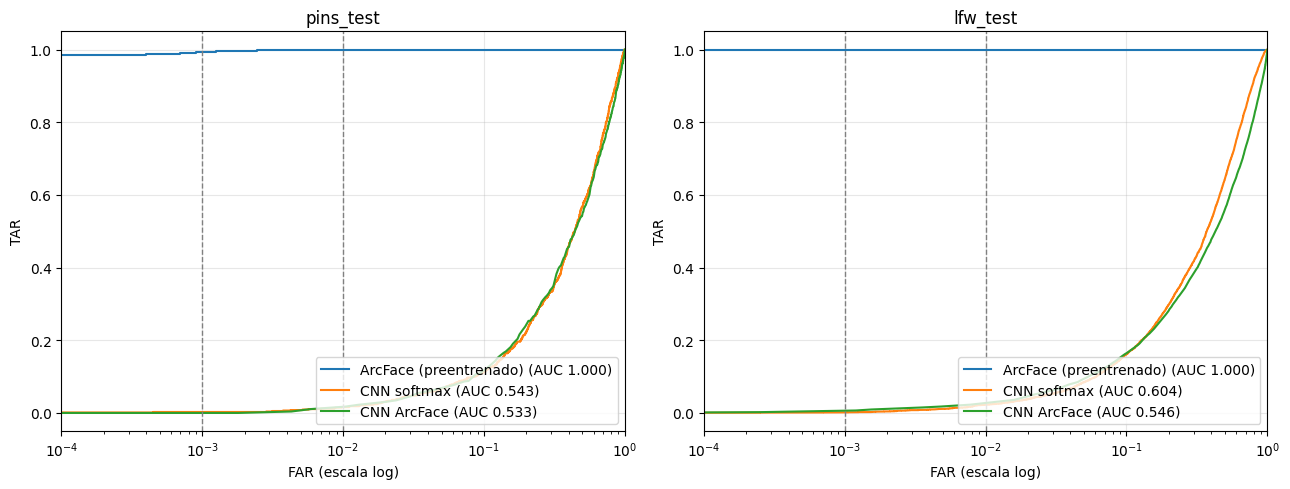

In [17]:
# Curvas ROC (FAR en escala logarítmica) en los dos conjuntos de test
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for eje, conjunto in zip(ejes, ["pins_test", "lfw_test"]):
    for modelo in emb:
        far, tar = curvas[modelo, conjunto]
        eje.semilogx(np.clip(far, 1e-5, None), tar, label=f"{modelo} (AUC {verificacion.loc[(conjunto, modelo), 'AUC']:.3f})")
    for objetivo in (1e-2, 1e-3):
        eje.axvline(objetivo, ls="--", color="gray", lw=1)
    eje.set(title=conjunto, xlabel="FAR (escala log)", ylabel="TAR", xlim=(1e-4, 1)); eje.legend(loc="lower right"); eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Figura 2. Curvas ROC de verificación de los tres modelos en `pins_test` y en `lfw_test`, con el FAR en escala logarítmica; las líneas punteadas marcan FAR = 1e-2 y 1e-3.*

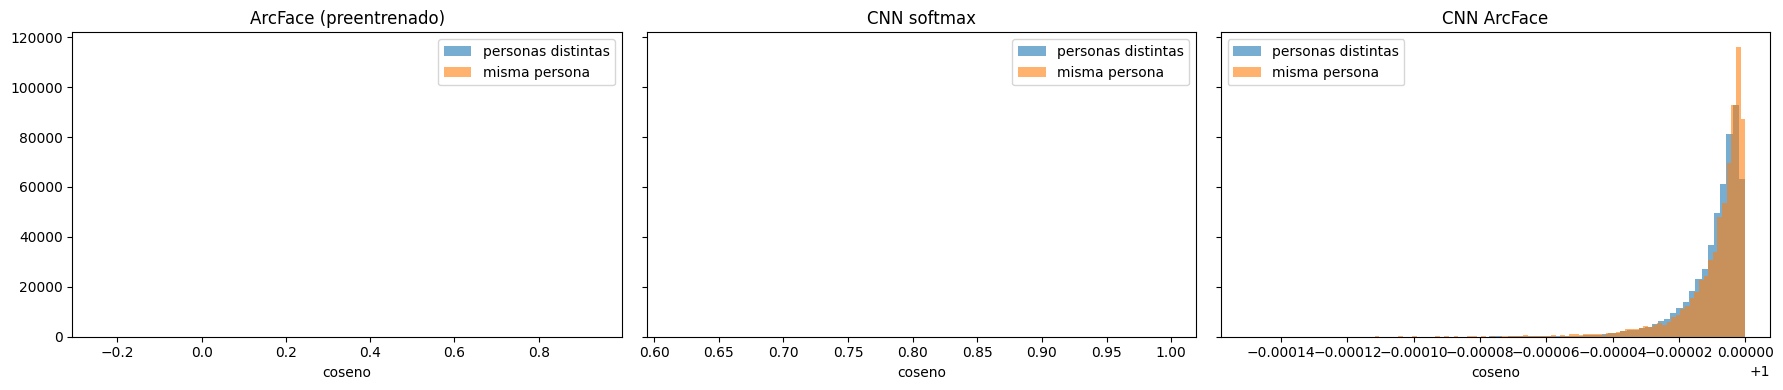

In [18]:
# Histograma de cosenos de pares positivos y negativos de cada modelo en lfw_test
fig, ejes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 4), sharey=True)
_, _, y_test = pares["lfw_test"]
for eje, modelo in zip(ejes, emb):
    s = puntajes[modelo, "lfw_test"]
    eje.hist(s[y_test == 0], bins=80, density=True, alpha=0.6, label="personas distintas")
    eje.hist(s[y_test == 1], bins=80, density=True, alpha=0.6, label="misma persona")
    eje.set(title=modelo, xlabel="coseno"); eje.legend()
plt.tight_layout()
plt.show()

*Figura 3. Distribución del coseno entre pares de la misma persona y de personas distintas en `lfw_test`, para cada modelo.*

*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

In [19]:
# Referencia externa: protocolo oficial de LFW (10 tandas; el umbral se elige en 9 y se mide la exactitud en la restante)
indice_eval = pd.Series(np.arange(len(evaluacion)), index=evaluacion["indice"])
filas_of = []
for modelo, e in emb.items():
    validos = pares_oficiales[pares_oficiales["indice_a"].isin(indice_eval.index) & pares_oficiales["indice_b"].isin(indice_eval.index)]
    s = (e[indice_eval[validos["indice_a"]].to_numpy()] * e[indice_eval[validos["indice_b"]].to_numpy()]).sum(axis=1)
    y = validos["misma_persona"].to_numpy()
    exactitudes = []
    for tanda in range(10):
        prueba = (validos["tanda"] == tanda).to_numpy()
        candidatos = np.unique(s[~prueba])
        mejor_umbral = max(candidatos[::max(1, len(candidatos) // 500)], key=lambda u: ((s[~prueba] >= u) == y[~prueba]).mean())
        exactitudes.append(((s[prueba] >= mejor_umbral) == y[prueba]).mean())
    filas_of.append({"modelo": modelo, "pares": len(validos), "exactitud media": np.mean(exactitudes), "desvío": np.std(exactitudes)})
pd.DataFrame(filas_of).set_index("modelo").round(4)

,pares,exactitud media,desvío
modelo,,,
ArcFace (preentrenado),5858,0.9985,0.0023
CNN softmax,5858,0.6007,0.0145
CNN ArcFace,5858,0.5463,0.0353


*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

## Elección del umbral

El umbral de la app (`SIMILARITY_THRESHOLD`) decide cuándo una cara es `unknown`. Se calibra en `lfw_val`, un conjunto que no se usa para reportar métricas, con un criterio fijado antes de mirar: el umbral que deja pasar como máximo un par de personas distintas cada mil (FAR = 1e-3). En una app que identifica personas, un falso positivo (tomar a alguien por otra persona) es más grave que un falso negativo (responder `unknown` y que haya que volver a intentar). Como control, también se informa el umbral del EER, donde FAR y FRR son iguales. Cada modelo tiene su propio umbral, porque sus cosenos tienen escalas distintas.

In [20]:
# Umbral de cada modelo en lfw_val: el que da FAR = 1e-3 y, como control, el del EER
FAR_OBJETIVO = 1e-3
_, _, y_val_pares = pares["lfw_val"]
umbrales = {}
for modelo in emb:
    s = puntajes[modelo, "lfw_val"]
    negativos, positivos = s[y_val_pares == 0], s[y_val_pares == 1]
    u_far = np.quantile(negativos, 1 - FAR_OBJETIVO)
    candidatos = np.linspace(s.min(), s.max(), 2001)
    far = np.array([(negativos >= u).mean() for u in candidatos]); frr = np.array([(positivos < u).mean() for u in candidatos])
    u_eer = candidatos[np.argmin(np.abs(far - frr))]
    umbrales[modelo] = {"umbral FAR=1e-3": u_far, "FRR con ese umbral": (positivos < u_far).mean(), "umbral EER": u_eer, "EER": far[np.argmin(np.abs(far - frr))], "curva": (candidatos, far, frr)}
pd.DataFrame({m: {k: v for k, v in d.items() if k != "curva"} for m, d in umbrales.items()}).T.round(4)

,umbral FAR=1e-3,FRR con ese umbral,umbral EER,EER
ArcFace (preentrenado),0.2014,0.0001,0.2448,0.0001
CNN softmax,0.9998,0.9935,0.9883,0.4266
CNN ArcFace,1.0000,0.9929,1.0000,0.4628


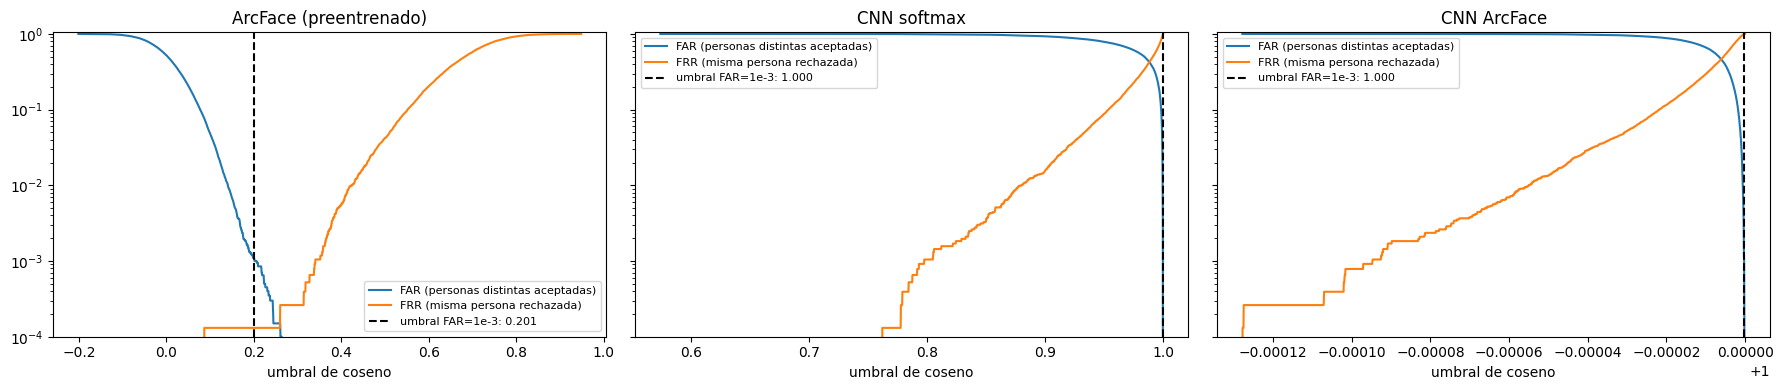

In [21]:
# FAR y FRR en función del umbral en lfw_val, con el umbral elegido de cada modelo
fig, ejes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 4), sharey=True)
for eje, modelo in zip(ejes, emb):
    candidatos, far, frr = umbrales[modelo]["curva"]
    eje.plot(candidatos, far, label="FAR (personas distintas aceptadas)")
    eje.plot(candidatos, frr, label="FRR (misma persona rechazada)")
    eje.axvline(umbrales[modelo]["umbral FAR=1e-3"], color="black", ls="--", label=f"umbral FAR=1e-3: {umbrales[modelo]['umbral FAR=1e-3']:.3f}")
    eje.set(title=modelo, xlabel="umbral de coseno", yscale="log", ylim=(1e-4, 1.05)); eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Figura 4. Tasa de falsos positivos (FAR) y de falsos negativos (FRR) en función del umbral, en `lfw_val`, con el umbral elegido de cada modelo.*

In [22]:
# El umbral calibrado en validación, aplicado en los conjuntos de test: FAR y FRR reales
filas_u = []
for modelo in emb:
    u = umbrales[modelo]["umbral FAR=1e-3"]
    for conjunto in ["lfw_val", "pins_test", "lfw_test"]:
        _, _, y = pares[conjunto]
        s = puntajes[modelo, conjunto]
        filas_u.append({"modelo": modelo, "conjunto": conjunto, "umbral": u, "FAR": (s[y == 0] >= u).mean(), "FRR": (s[y == 1] < u).mean()})
pd.DataFrame(filas_u).set_index(["modelo", "conjunto"]).round(4)

umbral     FAR     FRR
modelo                 conjunto                         
ArcFace (preentrenado) lfw_val    0.2014  0.0010  0.0001
                       pins_test  0.2014  0.0033  0.0013
                       lfw_test   0.2014  0.0010  0.0010
CNN softmax            lfw_val    0.9998  0.0010  0.9935
                       pins_test  0.9998  0.0004  0.9973
                       lfw_test   0.9998  0.0014  0.9976
CNN ArcFace            lfw_val    1.0000  0.0012  0.9929
                       pins_test  1.0000  0.0059  0.9893
                       lfw_test   1.0000  0.0016  0.9904

*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

## Identificación

La identificación imita la app: de cada persona conocida se registran 3 fotos en una galería (como tres `/insert`), y cada foto de consulta se compara con todos los registros; la identidad es la del registro más parecido, igual que en `identify`. Con el umbral calibrado, si el mejor coseno queda por debajo, la respuesta es `unknown`. En `lfw_test` son conocidas las personas con 4 o más fotos, y desconocidas las que tienen una sola. En `pins_test`, 10 de las 15 personas son conocidas y 5 se dejan afuera de la galería como desconocidas. Top-1 y Top-5 se miden sobre las consultas de personas conocidas, sin umbral. Precisión, recall y F1 (macro) se miden con umbral, contando `unknown` como una clase más.

In [23]:
# Galería (3 fotos por persona conocida) y consultas de cada conjunto de test
FOTOS_GALERIA = 3
DESCONOCIDAS_PINS = 5
rng_gal = np.random.default_rng(SEMILLA)

def armar_galeria(conjunto):
    """Índices de galería, de consultas y la identidad real de cada consulta (unknown si la persona no está en la galería)."""
    filas = evaluacion[evaluacion["split"] == conjunto]
    tamanos = filas.groupby("persona").size()
    if conjunto == "pins_test":
        desconocidas = set(rng_gal.choice(sorted(tamanos.index), DESCONOCIDAS_PINS, replace=False))
        conocidas = [p for p in sorted(tamanos.index) if p not in desconocidas]
    else:
        desconocidas = set(tamanos[tamanos == 1].index)
        conocidas = sorted(tamanos[tamanos > FOTOS_GALERIA].index)
    galeria, consultas, verdad = [], [], []
    for persona, g in filas.groupby("persona"):
        indices = rng_gal.permutation(g.index.to_numpy())
        if persona in conocidas:
            galeria += [(i, persona) for i in indices[:FOTOS_GALERIA]]
            consultas += list(indices[FOTOS_GALERIA:]); verdad += [persona] * (len(indices) - FOTOS_GALERIA)
        elif persona in desconocidas:
            consultas += list(indices); verdad += ["unknown"] * len(indices)
    return np.array([i for i, _ in galeria]), np.array([p for _, p in galeria]), np.array(consultas), np.array(verdad)

galerias = {c: armar_galeria(c) for c in ["pins_test", "lfw_test"]}
pd.DataFrame({c: {"personas en galería": len(set(gp)), "fotos en galería": len(gi), "consultas de conocidas": int((v != "unknown").sum()), "consultas de desconocidas": int((v == "unknown").sum())} for c, (gi, gp, q, v) in galerias.items()}).T

,personas en galería,fotos en galería,consultas de conocidas,consultas de desconocidas
pins_test,10,30,1369,836
lfw_test,282,846,1958,2009


In [24]:
# Top-1 y Top-5 (conocidas, sin umbral), y precisión, recall y F1 macro con el umbral calibrado, más el rechazo de desconocidas
from sklearn.metrics import precision_recall_fscore_support
filas_id, predicciones = [], {}
for modelo, e in emb.items():
    for conjunto, (gi, gp, q, verdad) in galerias.items():
        sim = e[q] @ e[gi].T
        personas_gal = np.unique(gp)
        por_persona = np.stack([sim[:, gp == p].max(axis=1) for p in personas_gal], axis=1)
        orden = np.argsort(-por_persona, axis=1)
        conocida = verdad != "unknown"
        top1 = (personas_gal[orden[conocida, 0]] == verdad[conocida]).mean()
        top5 = np.mean([v in personas_gal[o[:5]] for v, o in zip(verdad[conocida], orden[conocida])])
        mejor = por_persona.max(axis=1)
        prediccion = np.where(mejor >= umbrales[modelo]["umbral FAR=1e-3"], personas_gal[orden[:, 0]], "unknown")
        predicciones[modelo, conjunto] = prediccion
        p, r, f, _ = precision_recall_fscore_support(verdad, prediccion, average="macro", zero_division=0)
        filas_id.append({"modelo": modelo, "conjunto": conjunto, "Top-1": top1, "Top-5": top5, "precisión macro": p, "recall macro": r, "F1 macro": f,
                         "desconocidas rechazadas": (prediccion[~conocida] == "unknown").mean(), "conocidas rechazadas": (prediccion[conocida] == "unknown").mean(),
                         "azar Top-1": 1 / len(personas_gal)})
identificacion = pd.DataFrame(filas_id).set_index(["conjunto", "modelo"]).sort_index()
identificacion.round(4)

Top-1   Top-5  precisión macro  \
conjunto  modelo                                                    
lfw_test  ArcFace (preentrenado)  1.0000  1.0000           0.5637   
          CNN ArcFace             0.0163  0.0592           0.0096   
          CNN softmax             0.0107  0.0480           0.0067   
pins_test ArcFace (preentrenado)  0.9993  1.0000           0.9729   
          CNN ArcFace             0.1454  0.6289           0.1155   
          CNN softmax             0.1242  0.5566           0.1495   

                                  recall macro  F1 macro  \
conjunto  modelo                                           
lfw_test  ArcFace (preentrenado)        0.9985    0.6808   
          CNN ArcFace                   0.0096    0.0079   
          CNN softmax                   0.0078    0.0053   
pins_test ArcFace (preentrenado)        0.9944    0.9822   
          CNN ArcFace                   0.1017    0.0890   
          CNN softmax                   0.0933    0.0579   

                                  desconocidas rechazadas  \
conjunto  modelo                                            
lfw_test  ArcFace (preentrenado)                   0.5620   
          CNN ArcFace                              0.3320   
          CNN softmax                              0.6197   
pins_test ArcFace (preentrenado)                   0.9545   
          CNN ArcFace                              0.7667   
          CNN softmax                              0.9749   

                                  conocidas rechazadas  azar Top-1  
conjunto  modelo                                                    
lfw_test  ArcFace (preentrenado)                0.0000      0.0035  
          CNN ArcFace                           0.3544      0.0035  
          CNN softmax                           0.5945      0.0035  
pins_test ArcFace (preentrenado)                0.0015      0.1000  
          CNN ArcFace                           0.7641      0.1000  
          CNN softmax                           0.9788      0.1000

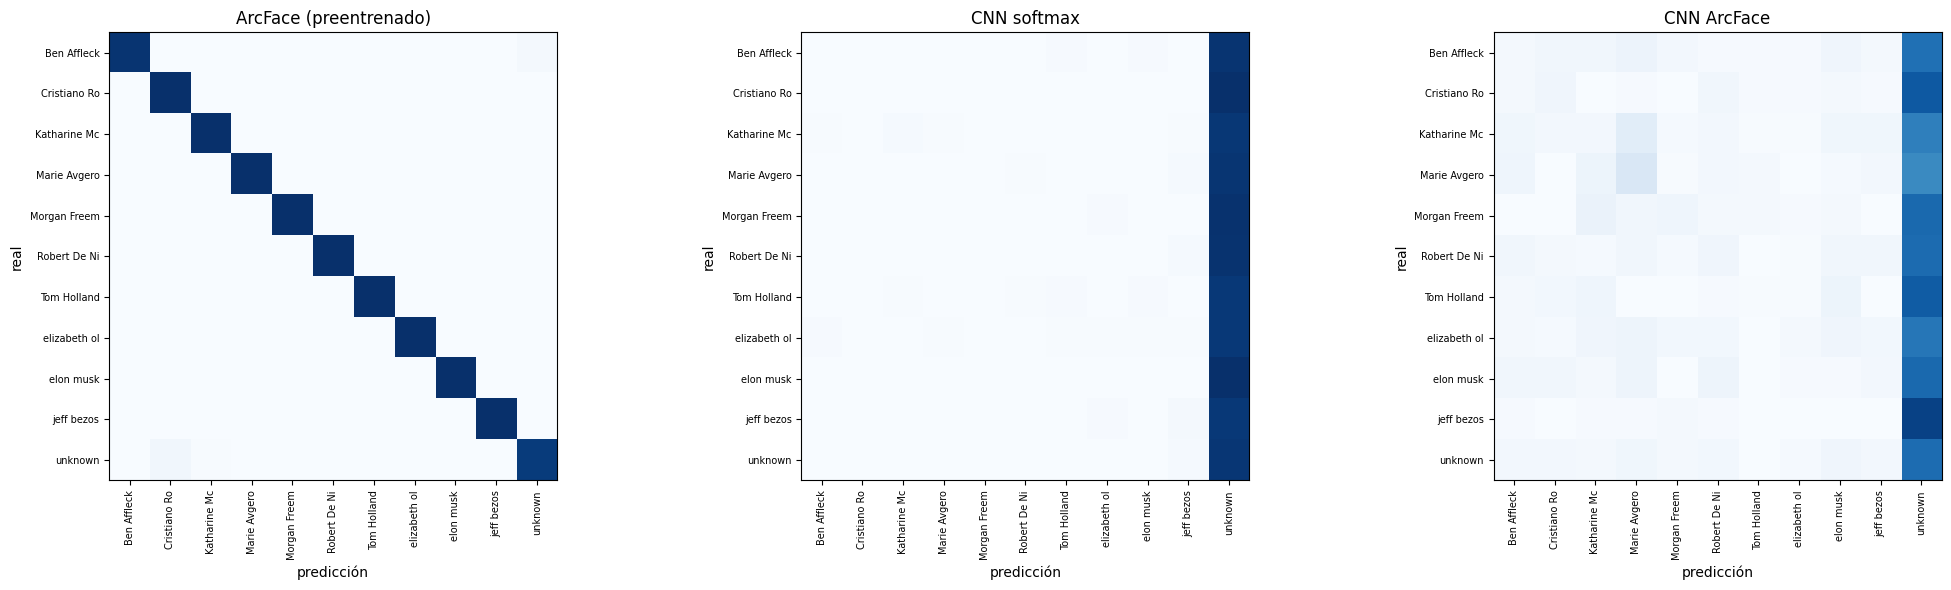

In [25]:
# Matriz de confusión en pins_test (10 personas conocidas más unknown) de cada modelo
from sklearn.metrics import confusion_matrix
_, _, _, verdad_pins = galerias["pins_test"]
etiquetas_conf = sorted(set(verdad_pins) - {"unknown"}) + ["unknown"]
fig, ejes = plt.subplots(1, len(emb), figsize=(7 * len(emb), 6))
for eje, modelo in zip(ejes, emb):
    matriz = confusion_matrix(verdad_pins, predicciones[modelo, "pins_test"], labels=etiquetas_conf, normalize="true")
    eje.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
    eje.set(title=modelo, xticks=range(len(etiquetas_conf)), yticks=range(len(etiquetas_conf)), xlabel="predicción", ylabel="real")
    eje.set_xticklabels([e[:12] for e in etiquetas_conf], rotation=90, fontsize=7); eje.set_yticklabels([e[:12] for e in etiquetas_conf], fontsize=7)
plt.tight_layout()
plt.show()

*Figura 5. Matriz de confusión normalizada por fila en `pins_test` (10 personas conocidas y `unknown`), con el umbral calibrado de cada modelo.*

In [26]:
# En lfw_test hay demasiadas personas para una matriz: los pares (real, predicción) más frecuentes entre los errores de cada modelo
for modelo in emb:
    _, _, _, verdad_lfw = galerias["lfw_test"]
    pred = predicciones[modelo, "lfw_test"]
    errores = pd.Series([f"{v} -> {p}" for v, p in zip(verdad_lfw, pred) if v != p])
    print(f"{modelo}: {len(errores)} errores de {len(pred)} consultas  |  más frecuentes: {errores.value_counts().head(5).to_dict()}")

ArcFace (preentrenado): 880 errores de 3967 consultas  |  más frecuentes: {'unknown -> Hugh_Grant': 9, 'unknown -> Donald_Rumsfeld': 9, 'unknown -> Gil_de_Ferran': 8, 'unknown -> Bill_McBride': 8, 'unknown -> Paul_Tagliabue': 8}
CNN softmax: 2714 errores de 3967 consultas  |  más frecuentes: {'Donald_Rumsfeld -> unknown': 50, 'Ariel_Sharon -> unknown': 46, 'Serena_Williams -> unknown': 39, 'Hugo_Chavez -> unknown': 38, 'Laura_Bush -> unknown': 26}
CNN ArcFace: 3276 errores de 3967 consultas  |  más frecuentes: {'Donald_Rumsfeld -> unknown': 54, 'Ariel_Sharon -> unknown': 35, 'unknown -> Sandra_Bullock': 23, 'Hugo_Chavez -> unknown': 21, 'unknown -> Tariq_Aziz': 20}


*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

## Clustering de los embeddings

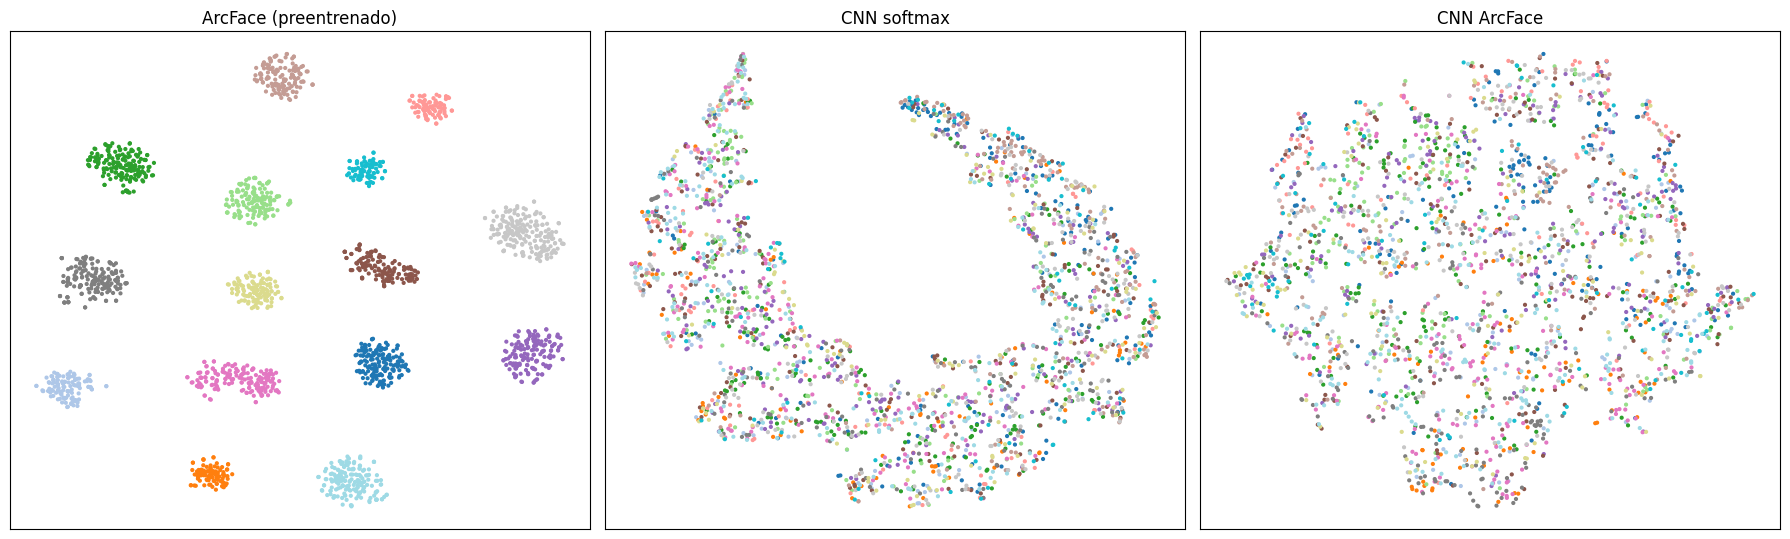

In [27]:
# t-SNE de los embeddings de pins_test de cada modelo, coloreados por persona
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
pins_eval = (evaluacion["split"] == "pins_test").to_numpy()
codigo_pins = pd.factorize(evaluacion.loc[pins_eval, "persona"])[0]
fig, ejes = plt.subplots(1, len(emb), figsize=(6 * len(emb), 5.5))
for eje, (modelo, e) in zip(ejes, emb.items()):
    proyeccion = TSNE(2, perplexity=30, max_iter=1000, init="pca", random_state=SEMILLA).fit_transform(e[pins_eval])
    eje.scatter(*proyeccion.T, c=codigo_pins, cmap="tab20", s=4)
    eje.set(title=modelo, xticks=[], yticks=[])
plt.tight_layout()
plt.show()

*Figura 6. Proyección t-SNE de los embeddings de `pins_test` (15 personas que la CNN no vio) de cada modelo, coloreada por persona.*

In [28]:
# Silhouette (etiquetas reales) y ARI y NMI del aglomerativo en pins_test y en las personas de lfw_test con 10 o más fotos
filas_cl = []
lfw_eval = (evaluacion["split"] == "lfw_test").to_numpy() & evaluacion.groupby("persona")["persona"].transform("size").ge(10).to_numpy()
for modelo, e in emb.items():
    for conjunto, m in [("pins_test", pins_eval), ("lfw_test (10 o más fotos)", lfw_eval)]:
        etiquetas = pd.factorize(evaluacion.loc[m, "persona"])[0]
        grupos = AgglomerativeClustering(etiquetas.max() + 1, metric="cosine", linkage="average").fit_predict(e[m])
        filas_cl.append({"conjunto": conjunto, "modelo": modelo, "personas": etiquetas.max() + 1, "silhouette": silhouette_score(e[m], etiquetas, metric="cosine"),
                         "ARI": adjusted_rand_score(etiquetas, grupos), "NMI": normalized_mutual_info_score(etiquetas, grupos)})
pd.DataFrame(filas_cl).set_index(["conjunto", "modelo"]).round(3)

,,personas,silhouette,ARI,NMI
conjunto,modelo,,,,
pins_test,ArcFace (preentrenado),15,0.514,1.000,1.000
lfw_test (10 o más fotos),ArcFace (preentrenado),77,0.625,0.996,0.998
pins_test,CNN softmax,15,-0.328,0.014,0.061
lfw_test (10 o más fotos),CNN softmax,77,-0.589,0.019,0.285
pins_test,CNN ArcFace,15,-0.175,0.008,0.051
lfw_test (10 o más fotos),CNN ArcFace,77,-0.495,0.015,0.282


*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

## Análisis de errores

In [29]:
def mostrar_pares(indices_a, indices_b, titulos, titulo_figura):
    """Muestra pares de caras alineadas, uno debajo del otro, con un título por par."""
    fig, ejes = plt.subplots(2, len(indices_a), figsize=(1.8 * len(indices_a), 4))
    for k, (a, b) in enumerate(zip(indices_a, indices_b)):
        for fila, i in enumerate((a, b)):
            ejes[fila, k].imshow(cv2.cvtColor(cv2.imread(evaluacion.at[i, "ruta_alineada"]), cv2.COLOR_BGR2RGB)); ejes[fila, k].axis("off")
            ejes[fila, k].set_title(evaluacion.at[i, "persona"][:16] if fila == 1 else f"{titulos[k]}\n{evaluacion.at[i, 'persona'][:16]}", fontsize=7)
    fig.suptitle(titulo_figura); plt.tight_layout(); plt.show()

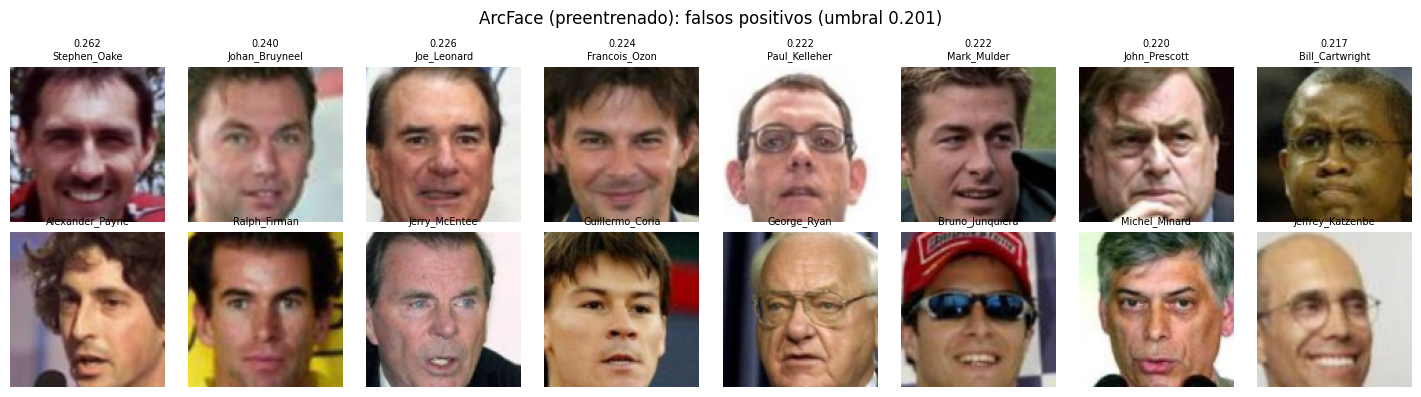

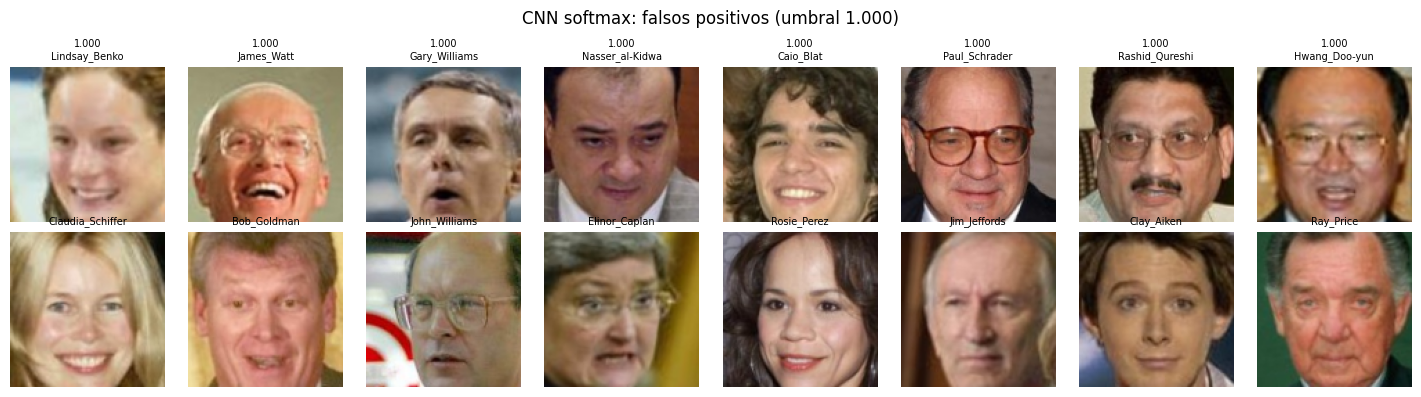

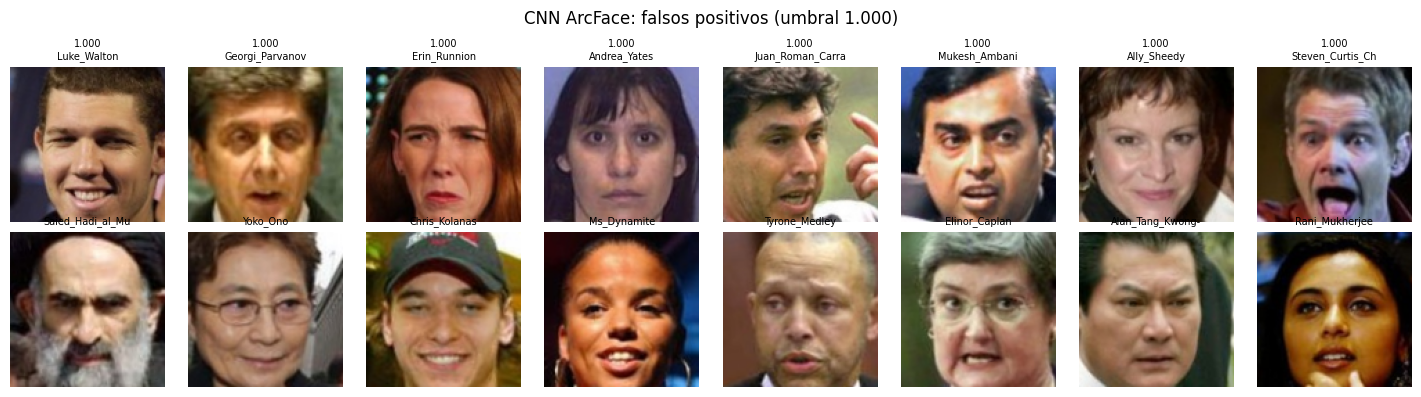

In [30]:
# Falsos positivos de cada modelo en lfw_test: los pares de personas distintas con coseno más alto
a, b, y = pares["lfw_test"]
for modelo in emb:
    s = puntajes[modelo, "lfw_test"]
    peores = np.argsort(-np.where(y == 0, s, -np.inf))[:8]
    mostrar_pares(a[peores], b[peores], [f"{s[k]:.3f}" for k in peores], f"{modelo}: falsos positivos (umbral {umbrales[modelo]['umbral FAR=1e-3']:.3f})")

*Figura 7. Los ocho pares de personas distintas con coseno más alto en `lfw_test`, para cada modelo (cada columna es un par, con el coseno arriba).*

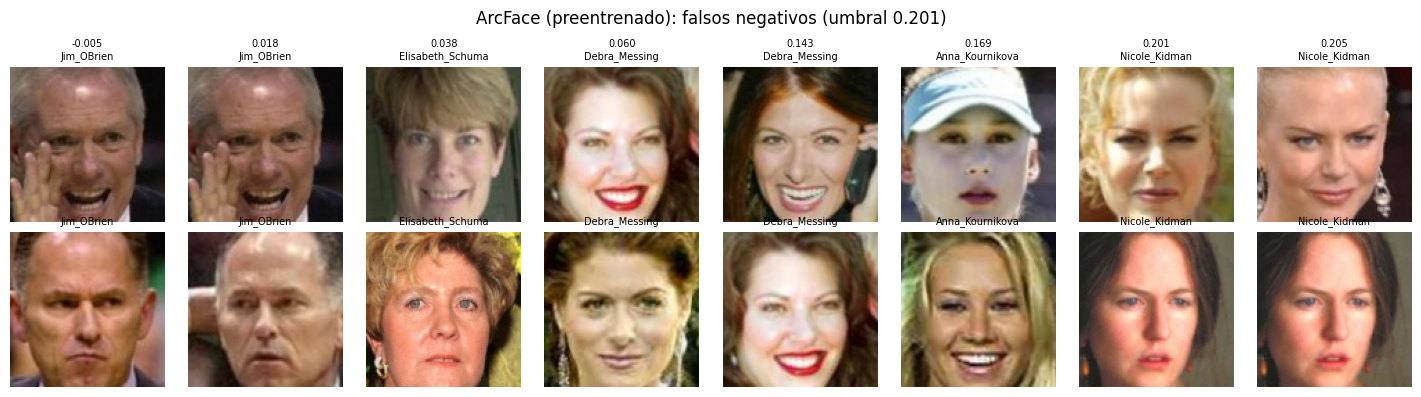

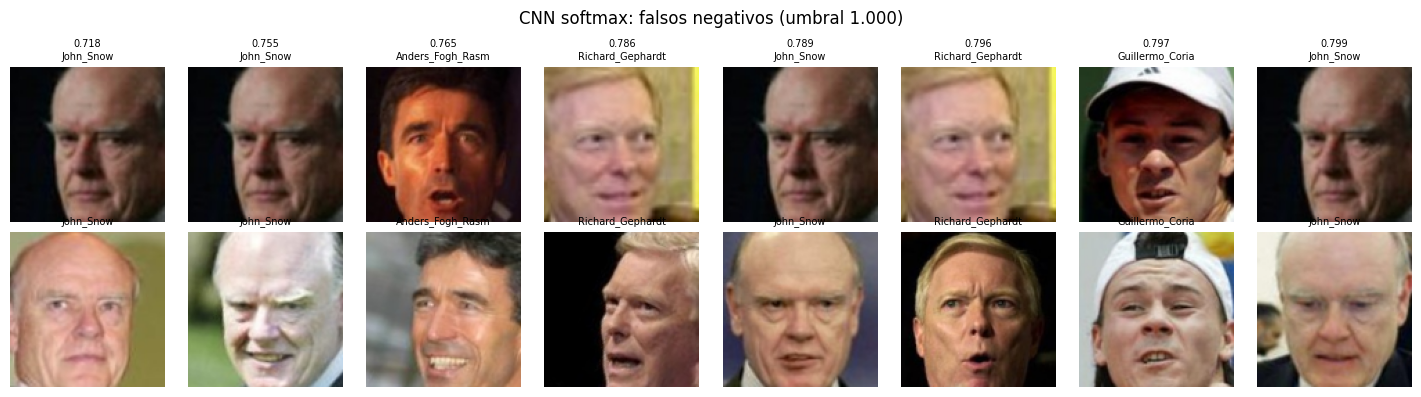

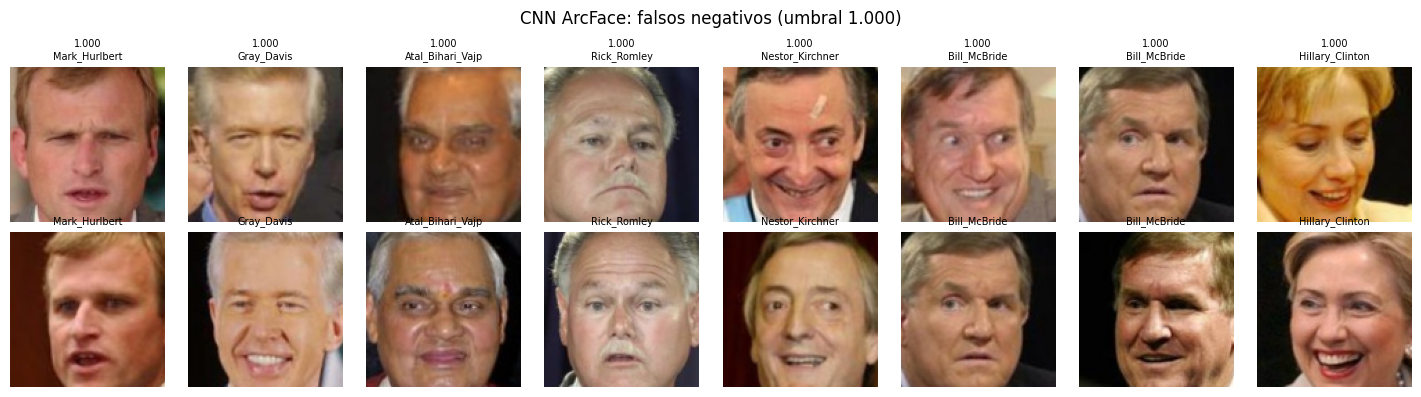

In [31]:
# Falsos negativos de cada modelo en lfw_test: los pares de la misma persona con coseno más bajo
for modelo in emb:
    s = puntajes[modelo, "lfw_test"]
    peores = np.argsort(np.where(y == 1, s, np.inf))[:8]
    mostrar_pares(a[peores], b[peores], [f"{s[k]:.3f}" for k in peores], f"{modelo}: falsos negativos (umbral {umbrales[modelo]['umbral FAR=1e-3']:.3f})")

*Figura 8. Los ocho pares de la misma persona con coseno más bajo en `lfw_test`, para cada modelo.*

*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

## Exportación del modelo A

In [32]:
# El experimento con mayor AUC en lfw_val (criterio fijado antes de entrenar) se exporta a ONNX y se verifica que la app lo carga y da los mismos embeddings
mejor_cnn = max(["CNN softmax", "CNN ArcFace"], key=lambda m: verificacion.loc[("lfw_val", m), "AUC"])
red_elegida = {"CNN softmax": red_softmax, "CNN ArcFace": red_arcface}[mejor_cnn]
RUTA_ONNX_CNN = RUTA_MODELOS / "cnn_custom.onnx"
export_onnx(copy.deepcopy(red_elegida).cpu(), RUTA_ONNX_CNN)
servicio_cnn = FaceService(store=None, similarity_metric="cosine", similarity_threshold=0.0, face_size=112, model_path=RUTA_ONNX_CNN, output_path=RUTA_INTERMEDIOS / "servicio")
muestra = evaluacion.sample(20, random_state=SEMILLA)
desde_app = np.array([servicio_cnn.extract_embedding_from_face(AlignedFace(bbox=None, keypoints=None, image=cv2.imread(r))) for r in muestra["ruta_alineada"]])
desde_red = emb[mejor_cnn][muestra.index]
print(f"Elegido: {mejor_cnn}  |  {RUTA_ONNX_CNN} ({RUTA_ONNX_CNN.stat().st_size / 1e6:.1f} MB)  |  coseno mínimo app vs. red: {(desde_app * desde_red).sum(axis=1).min():.6f}  |  dimensión: {desde_app.shape[1]}")

Elegido: CNN softmax  |  models/cnn_custom.onnx (5.2 MB)  |  coseno mínimo app vs. red: 1.000000  |  dimensión: 512


## Costo computacional

In [33]:
def tiempo_cpu(ruta):
    """Mediana en ms de una inferencia de una cara en CPU con onnxruntime."""
    sesion = ort.InferenceSession(str(ruta), providers=["CPUExecutionProvider"])
    entrada = {sesion.get_inputs()[0].name: FaceService.preprocess_face(cv2.imread(evaluacion.at[0, "ruta_alineada"]))}
    for _ in range(10):
        sesion.run(None, entrada)
    tiempos = []
    for _ in range(100):
        inicio = time.perf_counter(); sesion.run(None, entrada); tiempos.append(1000 * (time.perf_counter() - inicio))
    return np.median(tiempos)

In [34]:
# Tamaño, parámetros y tiempo de inferencia por cara en CPU (donde corre la app): 10 llamadas de calentamiento y la mediana de 100
import onnx
costo = pd.DataFrame({
    "ArcFace (preentrenado)": {"archivo": CONFIG_APP["MODEL_NAME"], "MB": (RUTA_MODELOS / CONFIG_APP["MODEL_NAME"]).stat().st_size / 1e6,
                               "parámetros (millones)": sum(np.prod(t.dims) for t in onnx.load(str(RUTA_MODELOS / CONFIG_APP["MODEL_NAME"])).graph.initializer) / 1e6,
                               "ms por cara (CPU)": tiempo_cpu(RUTA_MODELOS / CONFIG_APP["MODEL_NAME"]), "dimensión": EMBEDDING_DIM},
    f"CNN custom ({mejor_cnn})": {"archivo": RUTA_ONNX_CNN.name, "MB": RUTA_ONNX_CNN.stat().st_size / 1e6, "parámetros (millones)": parametros / 1e6,
                                  "ms por cara (CPU)": tiempo_cpu(RUTA_ONNX_CNN), "dimensión": EMBEDDING_DIM},
}).T
costo

,archivo,MB,parámetros (millones),ms por cara (CPU),dimensión
ArcFace (preentrenado),w600k_r50.onnx,174.38386,43.590976,150.68382,512
CNN custom (CNN softmax),cnn_custom.onnx,5.227455,1.305312,3.879957,512


*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*

## Comparación y elección

In [35]:
# Tabla comparativa de los modelos con las métricas de test (lfw_test, el escenario de la app, y pins_test, el mismo dominio que el entrenamiento)
comparacion = pd.concat({
    "verificación lfw_test": verificacion.xs("lfw_test")[["AUC", "EER", "TAR@FAR=1e-3"]],
    "verificación pins_test": verificacion.xs("pins_test")[["AUC", "EER", "TAR@FAR=1e-3"]],
    "identificación lfw_test": identificacion.xs("lfw_test")[["Top-1", "Top-5", "precisión macro", "recall macro", "F1 macro", "desconocidas rechazadas"]],
}, axis=1)
comparacion[("umbral", "FAR=1e-3 en lfw_val")] = pd.Series({m: d["umbral FAR=1e-3"] for m, d in umbrales.items()})
comparacion.round(4)

verificación lfw_test                       \
                                         AUC     EER TAR@FAR=1e-3   
modelo                                                              
ArcFace (preentrenado)                0.9998  0.0010       0.9992   
CNN ArcFace                           0.5462  0.4684       0.0040   
CNN softmax                           0.6037  0.4309       0.0017   

                       verificación pins_test                       \
                                          AUC     EER TAR@FAR=1e-3   
modelo                                                               
ArcFace (preentrenado)                 0.9999  0.0026       0.9920   
CNN ArcFace                            0.5334  0.4721       0.0000   
CNN softmax                            0.5427  0.4683       0.0027   

                       identificación lfw_test                          \
                                         Top-1   Top-5 precisión macro   
modelo                                                                   
ArcFace (preentrenado)                  1.0000  1.0000          0.5637   
CNN ArcFace                             0.0163  0.0592          0.0096   
CNN softmax                             0.0107  0.0480          0.0067   

                                                                      \
                       recall macro F1 macro desconocidas rechazadas   
modelo                                                                 
ArcFace (preentrenado)       0.9985   0.6808                  0.5620   
CNN ArcFace                  0.0096   0.0079                  0.3320   
CNN softmax                  0.0078   0.0053                  0.6197   

                                    umbral  
                       FAR=1e-3 en lfw_val  
modelo                                      
ArcFace (preentrenado)              0.2014  
CNN ArcFace                         1.0000  
CNN softmax                         0.9998

*(Lectura pendiente: se escribe con los números de la corrida completa en GPU.)*